# Desenvolvimento de Modelo de PD (Probability of Default)

## Fase 1: Estruturação da Base e Definição de Target
- **Definição da população elegível (`t = 0`):** Filtrei a base (`Dados_PD.csv`) na data de observação (`safra_obs`) para manter apenas a carteira ativa e adimplente, removendo contratos cancelados ou que já estavam em default (mais de 90 dias de atraso) antes da foto inicial.
- **Padronização da janela de performance:** Fixei o horizonte de acompanhamento em **12 meses** após a `safra_obs`, seguindo o padrão regulatório de Basileia e IFRS 9 — tiro uma foto do cliente hoje e observo seu comportamento ao longo de um ano.
- **Construção da variável-alvo (`default_12m`):** Marquei como `1` (Mau) todo cliente que atingiu atraso superior a 90 dias em qualquer momento dentro da janela de 12 meses, e como `0` (Bom) quem atravessou o período sem entrar em default.
- **Tratamento de contratos indeterminados (produção):** Para cenários reais onde o cliente encerra o contrato antes dos 12 meses sem ter atrasado, estabeleci a regra de mantê-lo como `0` (Bom) caso tenha completado ao menos 6 meses de observação, ou removê-lo do treino para não gerar ruído no modelo.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('Dados.csv')
df

,safra_obs,renda_mensal,limite,saldo,utilizacao_inicial,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,default_12m
0,2023,2656.21,6940.73,1136.32,0.1637,-0.2395,0,0,0
1,2025,10616.39,21858.40,2388.10,0.1093,-0.2630,0,0,0
2,2024,8373.60,21731.54,13327.06,0.6133,0.4879,1,1,0
3,2024,5247.29,14085.84,12377.01,0.8787,0.1578,0,0,0
4,2022,3067.02,11915.43,9174.16,0.7699,0.0705,0,0,0
...,...,...,...,...,...,...,...,...,...
29995,2025,2625.82,4390.83,4176.63,0.9512,-0.0614,0,0,1
29996,2024,3612.29,13835.69,7462.13,0.5393,0.2415,0,0,0
29997,2022,3760.22,6745.34,2361.42,0.3501,0.0923,0,0,0
29998,2023,7066.38,12857.03,11194.97,0.8707,0.2381,0,0,0


## Análise Exploratória e Engenharia de Atributos (Features)
- **Tratamento de multicolinearidade:** Evitei colocar `saldo`, `limite` e `utilizacao_inicial` simultaneamente na Regressão Logística, pois `utilizacao_inicial` é a razão exata entre `saldo` e `limite` — manter as três juntas criaria redundância e distorceria os coeficientes do modelo.
- **Criação de razões financeiras de capacidade de pagamento:** Construí novos indicadores para medir o fôlego financeiro real de cada cliente além dos valores absolutos:
  - `comprometimento_renda = saldo / renda_mensal`
  - `alavancagem_limite = limite / renda_mensal`
  - `limite_restante = limite - saldo` (folga de limite disponível)
- **Avaliação de poder preditivo univariado (IV - Information Value):**
  - Agrupei as variáveis contínuas em faixas (*binning*) para analisar a concentração de bons e maus pagadores em cada intervalo.
  - Calculei o **IV** de cada atributo como filtro de seleção: descartei as variáveis sem poder preditivo (`IV < 0.02`) e verifiquei se nenhuma apresentava valores suspeitos (`IV > 0.50`) que pudessem indicar vazamento de dados (*data leakage*).

In [2]:
df['percentual_uso'] = df['saldo'] / df['limite']

df['comprometimento_renda'] = df['saldo'] / df['renda_mensal']

df['alavancagem_limite'] = df['limite'] / df['renda_mensal']

df['limite_restante'] = df['limite'] - df['saldo']


df

,safra_obs,renda_mensal,limite,saldo,utilizacao_inicial,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,default_12m,percentual_uso,comprometimento_renda,alavancagem_limite,limite_restante
0,2023,2656.21,6940.73,1136.32,0.1637,-0.2395,0,0,0,0.163718,0.427798,2.613020,5804.41
1,2025,10616.39,21858.40,2388.10,0.1093,-0.2630,0,0,0,0.109253,0.224945,2.058930,19470.30
2,2024,8373.60,21731.54,13327.06,0.6133,0.4879,1,1,0,0.613259,1.591557,2.595245,8404.48
3,2024,5247.29,14085.84,12377.01,0.8787,0.1578,0,0,0,0.878685,2.358743,2.684403,1708.83
4,2022,3067.02,11915.43,9174.16,0.7699,0.0705,0,0,0,0.769939,2.991229,3.885019,2741.27
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,2025,2625.82,4390.83,4176.63,0.9512,-0.0614,0,0,1,0.951217,1.590600,1.672175,214.20
29996,2024,3612.29,13835.69,7462.13,0.5393,0.2415,0,0,0,0.539339,2.065762,3.830171,6373.56
29997,2022,3760.22,6745.34,2361.42,0.3501,0.0923,0,0,0,0.350082,0.628000,1.793868,4383.92
29998,2023,7066.38,12857.03,11194.97,0.8707,0.2381,0,0,0,0.870728,1.584258,1.819465,1662.06


## Como o cálculo do Information Value (IV) funciona na prática

- **Categorização (*Binning*):** Fatiei cada variável contínua em grupos ordenados — por exemplo, dividi `utilizacao_inicial` em três faixas (`0% a 30%`, `30% a 70%` e `70% a 100%`). Busquei manter o *binning* monotônico, garantindo que a taxa de calote subisse ou descesse de forma contínua de uma faixa para a outra.
- **Comparação de proporções:** Em cada faixa, comparei o percentual de **Bons** pagadores contra o percentual de **Maus** pagadores. Quando uma faixa como `70% a 100%` concentra uma fatia alta dos calotes da carteira e uma fatia baixa dos bons pagadores, fica claro que a variável separa bem os dois perfis.
- **Soma ponderada (IV):** Consolidei essas diferenças ao longo de todas as faixas para chegar a uma nota única de poder preditivo por variável:

$$IV = \sum_{i=1}^{k} (\%\text{Bons}_i - \%\text{Maus}_i) \times \ln\left(\frac{\%\text{Bons}_i}{\%\text{Maus}_i}\right)$$

---

## Régua de decisão que adotei para o IV

- **Menor que 0,02:** Sem poder preditivo — descartei a variável da modelagem.
- **Entre 0,02 e 0,10:** Poder preditivo fraco — mantive apenas quando ajudava a complementar o sinal de outras variáveis.
- **Entre 0,10 e 0,30:** Poder preditivo médio — bons candidatos que levei para a etapa de modelagem.
- **Entre 0,30 e 0,50:** Poder preditivo forte — variáveis principais do modelo.
- **Maior que 0,50:** Forte demais — tratei como sinal de alerta para investigar possível vazamento de dados (*data leakage*), como variáveis registradas somente depois que o cliente já entrou em atraso.

In [3]:
regras_faixas = {
    "utilizacao_inicial":    ([-np.inf, 0.30, 0.70, np.inf], ["0% a 30%", "30% a 70%", "70% a 100%"]),
    "percentual_uso":        ([-np.inf, 0.30, 0.70, np.inf], ["0% a 30%", "30% a 70%", "70% a 100%"]),
    "renda_mensal":          ([-np.inf, 2500, 5000, 8000, np.inf], ["Até R$ 2.500", "R$ 2.500 a R$ 5.000", "R$ 5.000 a R$ 8.000", "Acima de R$ 8.000"]),
    "limite":                ([-np.inf, 5000, 10000, 20000, np.inf], ["Até R$ 5.000", "R$ 5.000 a R$ 10.000", "R$ 10.000 a R$ 20.000", "Acima de R$ 20.000"]),
    "saldo":                 ([-np.inf, 1500, 4000, 8000, np.inf], ["Até R$ 1.500", "R$ 1.500 a R$ 4.000", "R$ 4.000 a R$ 8.000", "Acima de R$ 8.000"]),
    "variacao_saldo_3m":     ([-np.inf, -0.05, 0.15, 0.35, np.inf], ["Queda (< -5%)", "Estável (-5% a +15%)", "Alta moderada (+15% a +35%)", "Alta forte (> +35%)"]),
    "comprometimento_renda": ([-np.inf, 0.50, 1.00, 2.00, np.inf], ["Até 50% da renda", "50% a 100% da renda", "1x a 2x a renda", "Acima de 2x a renda"]),
    "alavancagem_limite":    ([-np.inf, 2.0, 3.0, np.inf], ["Até 2x a renda", "2x a 3x a renda", "Acima de 3x a renda"]),
    "limite_restante":       ([-np.inf, 2000, 5000, 10000, np.inf], ["Até R$ 2.000", "R$ 2.000 a R$ 5.000", "R$ 5.000 a R$ 10.000", "Acima de R$ 10.000"]),
    "qtd_atrasos_curtos_6m": ([-np.inf, 0, 1, np.inf], ["0 atrasos", "1 atraso", "2+ atrasos"]),
}

for col, (cortes, nomes) in regras_faixas.items():
    df[f"{col}_faixa"] = pd.cut(df[col], bins=cortes, labels=nomes)

df



,safra_obs,renda_mensal,limite,saldo,utilizacao_inicial,variacao_saldo_3m,qtd_atrasos_curtos_6m,pagou_minimo_ult_fatura,default_12m,percentual_uso,...,utilizacao_inicial_faixa,percentual_uso_faixa,renda_mensal_faixa,limite_faixa,saldo_faixa,variacao_saldo_3m_faixa,comprometimento_renda_faixa,alavancagem_limite_faixa,limite_restante_faixa,qtd_atrasos_curtos_6m_faixa
0,2023,2656.21,6940.73,1136.32,0.1637,-0.2395,0,0,0,0.163718,...,0% a 30%,0% a 30%,R$ 2.500 a R$ 5.000,R$ 5.000 a R$ 10.000,Até R$ 1.500,Queda (< -5%),Até 50% da renda,2x a 3x a renda,R$ 5.000 a R$ 10.000,0 atrasos
1,2025,10616.39,21858.40,2388.10,0.1093,-0.2630,0,0,0,0.109253,...,0% a 30%,0% a 30%,Acima de R$ 8.000,Acima de R$ 20.000,R$ 1.500 a R$ 4.000,Queda (< -5%),Até 50% da renda,2x a 3x a renda,Acima de R$ 10.000,0 atrasos
2,2024,8373.60,21731.54,13327.06,0.6133,0.4879,1,1,0,0.613259,...,30% a 70%,30% a 70%,Acima de R$ 8.000,Acima de R$ 20.000,Acima de R$ 8.000,Alta forte (> +35%),1x a 2x a renda,2x a 3x a renda,R$ 5.000 a R$ 10.000,1 atraso
3,2024,5247.29,14085.84,12377.01,0.8787,0.1578,0,0,0,0.878685,...,70% a 100%,70% a 100%,R$ 5.000 a R$ 8.000,R$ 10.000 a R$ 20.000,Acima de R$ 8.000,Alta moderada (+15% a +35%),Acima de 2x a renda,2x a 3x a renda,Até R$ 2.000,0 atrasos
4,2022,3067.02,11915.43,9174.16,0.7699,0.0705,0,0,0,0.769939,...,70% a 100%,70% a 100%,R$ 2.500 a R$ 5.000,R$ 10.000 a R$ 20.000,Acima de R$ 8.000,Estável (-5% a +15%),Acima de 2x a renda,Acima de 3x a renda,R$ 2.000 a R$ 5.000,0 atrasos
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,2025,2625.82,4390.83,4176.63,0.9512,-0.0614,0,0,1,0.951217,...,70% a 100%,70% a 100%,R$ 2.500 a R$ 5.000,Até R$ 5.000,R$ 4.000 a R$ 8.000,Queda (< -5%),1x a 2x a renda,Até 2x a renda,Até R$ 2.000,0 atrasos
29996,2024,3612.29,13835.69,7462.13,0.5393,0.2415,0,0,0,0.539339,...,30% a 70%,30% a 70%,R$ 2.500 a R$ 5.000,R$ 10.000 a R$ 20.000,R$ 4.000 a R$ 8.000,Alta moderada (+15% a +35%),Acima de 2x a renda,Acima de 3x a renda,R$ 5.000 a R$ 10.000,0 atrasos
29997,2022,3760.22,6745.34,2361.42,0.3501,0.0923,0,0,0,0.350082,...,30% a 70%,30% a 70%,R$ 2.500 a R$ 5.000,R$ 5.000 a R$ 10.000,R$ 1.500 a R$ 4.000,Estável (-5% a +15%),50% a 100% da renda,Até 2x a renda,R$ 2.000 a R$ 5.000,0 atrasos
29998,2023,7066.38,12857.03,11194.97,0.8707,0.2381,0,0,0,0.870728,...,70% a 100%,70% a 100%,R$ 5.000 a R$ 8.000,R$ 10.000 a R$ 20.000,Acima de R$ 8.000,Alta moderada (+15% a +35%),1x a 2x a renda,Até 2x a renda,Até R$ 2.000,0 atrasos


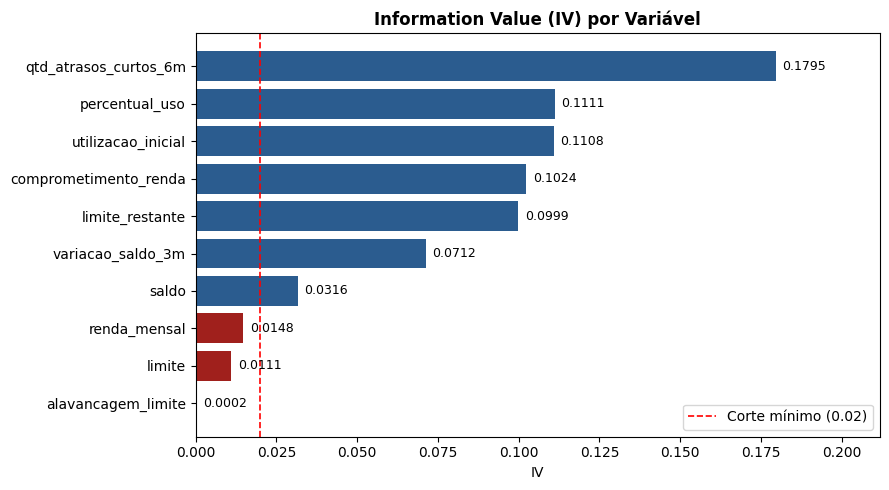

             Variavel     IV     Poder_Preditivo
qtd_atrasos_curtos_6m 0.1795 Médio (0.10 a 0.30)
       percentual_uso 0.1111 Médio (0.10 a 0.30)
   utilizacao_inicial 0.1108 Médio (0.10 a 0.30)
comprometimento_renda 0.1024 Médio (0.10 a 0.30)
      limite_restante 0.0999 Fraco (0.02 a 0.10)
    variacao_saldo_3m 0.0712 Fraco (0.02 a 0.10)
                saldo 0.0316 Fraco (0.02 a 0.10)
         renda_mensal 0.0148  Descartar (< 0.02)
               limite 0.0111  Descartar (< 0.02)
   alavancagem_limite 0.0002  Descartar (< 0.02)


In [4]:
resultados = []

for variavel in regras_faixas.keys():
    coluna_faixa = f"{variavel}_faixa"
    tabela = pd.crosstab(df[coluna_faixa], df["default_12m"])
    tabela.columns = ["Bons", "Maus"]
    
    pct_bons = np.maximum(tabela["Bons"] / tabela["Bons"].sum(), 0.0001)
    pct_maus = np.maximum(tabela["Maus"] / tabela["Maus"].sum(), 0.0001)
    
    iv = ((pct_bons - pct_maus) * np.log(pct_bons / pct_maus)).sum()
    
    if iv < 0.02:
        status = "Descartar (< 0.02)"
    elif iv < 0.10:
        status = "Fraco (0.02 a 0.10)"
    elif iv < 0.30:
        status = "Médio (0.10 a 0.30)"
    else:
        status = "Forte (> 0.30)"
        
    resultados.append({"Variavel": variavel, "IV": round(iv, 4), "Poder_Preditivo": status})

df_iv = pd.DataFrame(resultados).sort_values("IV", ascending=True)


cores = ["#a0201c" if iv < 0.02 else "#2b5c8f" for iv in df_iv["IV"]]

plt.figure(figsize=(9, 5))
barras = plt.barh(df_iv["Variavel"], df_iv["IV"], color=cores)


plt.axvline(0.02, color="red", linestyle="--", linewidth=1.2, label="Corte mínimo (0.02)")


for barra in barras:
    valor = barra.get_width()
    plt.text(valor + 0.002, barra.get_y() + barra.get_height() / 2, f"{valor:.4f}", va="center", fontsize=9)

plt.title("Information Value (IV) por Variável", fontsize=12, fontweight="bold")
plt.xlabel("IV")
plt.xlim(0, df_iv["IV"].max() * 1.18)
plt.legend()
plt.tight_layout()
plt.show()


print(df_iv.sort_values("IV", ascending=False).to_string(index=False))

## Estratégia de Validação e Divisão das Safras
- **In-Time (treino):** o modelo é ajustado nas safras de 2022 a 2024.
- **Out-of-Time (validação):** o desempenho é medido na safra de 2025 (`safra_obs == 2025`), reservada exclusivamente para o teste temporal final e sem nenhum contato prévio durante o ajuste. Isso simula o uso real do modelo em dados futuros.
- **Verificação da estabilidade temporal (Bad Rate por safra):** Conferi a evolução da taxa média de default entre 2022 e 2025 para garantir que o comportamento da carteira era consistente ao longo do tempo e descartar choques macroeconômicos que exigissem recalibração.

In [5]:
treino = df[df['safra_obs'].isin([2022, 2023, 2024])]
teste = df[df['safra_obs']== 2025]

df.groupby('safra_obs')['default_12m'].mean().reset_index(name ='média de default')

,safra_obs,média de default
0,2022,0.069232
1,2023,0.069718
2,2024,0.069552
3,2025,0.075619


## Treinamento e Calibração do Modelo
- **Treinamento do modelo (Regressão Logística):** Ajustei a Regressão Logística utilizando apenas as variáveis aprovadas no filtro de IV e sem multicolinearidade, padronizando suas escalas com `StandardScaler` (ajustado exclusivamente na base de treino para evitar vazamento de dados). Optei pela Regressão Logística por oferecer transparência total nos pesos de cada variável, facilidade de auditoria e governança.
- **Calibração natural das probabilidades:** Como treinei a Regressão Logística diretamente sobre a distribuição original da carteira, as probabilidades previstas já saem calibradas de fábrica, refletindo a taxa real de default observada sem exigir ajustes posteriores.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve


features = ['qtd_atrasos_curtos_6m', 'percentual_uso', 'utilizacao_inicial', 'comprometimento_renda', 'limite_restante', 'variacao_saldo_3m', 'saldo']


X_treino, y_treino = treino[features], treino['default_12m']
X_teste, y_teste = teste[features], teste['default_12m']

scaler = StandardScaler()
X_treino_sc = scaler.fit_transform(X_treino)
X_teste_sc = scaler.transform(X_teste)


modelo = LogisticRegression()
modelo.fit(X_treino_sc, y_treino)


pd_treino = modelo.predict_proba(X_treino_sc)[:, 1]
pd_teste = modelo.predict_proba(X_teste_sc)[:, 1]



## Avaliação de Performance e Estabilidade
- **Métricas de discriminação (ordenação de risco):** Avaliei a capacidade do modelo de separar bons e maus pagadores comparando o desempenho entre o Treino (2022–2024) e o OOT (2025) por meio de três indicadores:
  - **AUC-ROC:** Medi o poder geral de classificação do modelo ao longo de todos os pontos de corte possíveis.
  - **Gini (`2 * AUC - 1`):** Utilizei como régua de comparação com o mercado de crédito (referência próxima a `0,40` para modelos comportamentais).
  - **KS (Kolmogorov-Smirnov):** Calculei a distância máxima entre as curvas acumuladas de bons e maus pagadores (referência de mercado em torno de `0,30`) para confirmar a força de separação.
- **Métricas de calibração e estabilidade:**
  - **Brier Score e Curva de Calibração:** Verifiquei se as probabilidades previstas acompanhavam a taxa real de default (*Bad Rate*) observada em cada decil de score na safra 2025, garantindo aderência numérica além da simples ordenação.
  - **PSI (*Population Stability Index*):** Medi o deslocamento da distribuição dos scores entre o período histórico (2022–2024) e a safra futura (2025), confirmando estabilidade populacional (`PSI < 0,10`, bem abaixo do limite crítico de `0,25`).
- **Construção da Matriz de Ratings (faixas de risco):** Agrupei os scores previstos em faixas homogêneas de risco (Ratings de **A** a **H**) usando os cortes fixados no treino e validei a monotonicidade da taxa de default na safra 2025, assegurando que o risco subisse de forma consistente a cada degrau.

In [7]:
def metricas_discriminacao(y_real, prob):
    auc = roc_auc_score(y_real, prob)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_real, prob)
    ks = np.max(tpr - fpr)
    return round(auc, 4), round(gini, 4), round(ks, 4)

auc_tr, gini_tr, ks_tr = metricas_discriminacao(y_treino, pd_treino)
auc_te, gini_te, ks_te = metricas_discriminacao(y_teste, pd_teste)

print("=== 1. DISCRIMINAÇÃO ===")
print(f"Treino (2022-2024) -> AUC: {auc_tr} | Gini: {gini_tr} | KS: {ks_tr}")
print(f"Teste OOT (2025)   -> AUC: {auc_te} | Gini: {gini_te} | KS: {ks_te}\n")

=== 1. DISCRIMINAÇÃO ===
Treino (2022-2024) -> AUC: 0.6756 | Gini: 0.3512 | KS: 0.2547
Teste OOT (2025)   -> AUC: 0.6869 | Gini: 0.3738 | KS: 0.2973



=== 2. CALIBRAÇÃO E ESTABILIDADE ===
Brier Score (2025):   0.0674
PSI (Treino vs 2025): 0.0012 -> Estável (< 0.10)



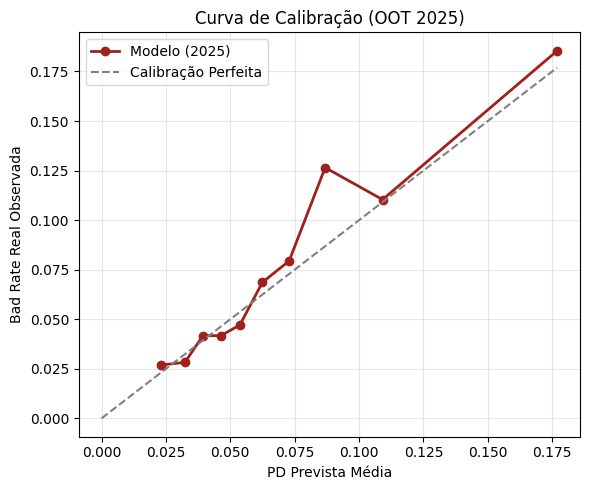

In [8]:
brier = brier_score_loss(y_teste, pd_teste)

def calcular_psi(esperado, atual, bins=10):
    cortes = np.quantile(esperado, np.linspace(0, 1, bins + 1))
    cortes[0], cortes[-1] = -np.inf, np.inf
    esp_pct = np.maximum(np.histogram(esperado, bins=cortes)[0] / len(esperado), 0.0001)
    atu_pct = np.maximum(np.histogram(atual, bins=cortes)[0] / len(atual), 0.0001)
    return np.sum((atu_pct - esp_pct) * np.log(atu_pct / esp_pct))

psi = calcular_psi(pd_treino, pd_teste, bins=10)

print("=== 2. CALIBRAÇÃO E ESTABILIDADE ===")
print(f"Brier Score (2025):   {brier:.4f}")
print(f"PSI (Treino vs 2025): {psi:.4f} -> {'Estável (< 0.10)' if psi < 0.10 else 'Atenção (>= 0.10)'}\n")


prob_real, prob_prev = calibration_curve(y_teste, pd_teste, n_bins=10, strategy="quantile")

plt.figure(figsize=(6, 5))
plt.plot(prob_prev, prob_real, marker="o", linewidth=2, label="Modelo (2025)", color = "#a0201c")
plt.plot([0, prob_prev.max()], [0, prob_prev.max()], linestyle="--", color="gray", label="Calibração Perfeita")
plt.title("Curva de Calibração (OOT 2025)")
plt.xlabel("PD Prevista Média")
plt.ylabel("Bad Rate Real Observada")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
df_oot = teste.copy()
df_oot["pd_prevista"] = pd_teste


cortes_rating = np.quantile(pd_treino, np.linspace(0, 1, 9))
cortes_rating[0], cortes_rating[-1] = -np.inf, np.inf
ratings = ["A", "B", "C", "D", "E", "F", "G", "H"]

df_oot["Rating"] = pd.cut(df_oot["pd_prevista"], bins=cortes_rating, labels=ratings)

matriz_ratings = df_oot.groupby("Rating", observed=False).agg(
    Clientes=("default_12m", "count"),
    Pct_Carteira=("default_12m", lambda x: round(len(x) / len(df_oot) * 100, 1)),
    Maus=("default_12m", "sum"),
    PD_Prevista_Media=("pd_prevista", lambda x: round(x.mean() * 100, 2)),
    Bad_Rate_Real=("default_12m", lambda x: round(x.mean() * 100, 2)),
)

print("=== 3. MATRIZ DE RATINGS (OOT 2025) ===")
print(matriz_ratings)

=== 3. MATRIZ DE RATINGS (OOT 2025) ===
        Clientes  Pct_Carteira  Maus  PD_Prevista_Media  Bad_Rate_Real
Rating                                                                
A            903          12.2    24               2.41           2.66
B            893          12.0    31               3.47           3.47
C            909          12.2    33               4.30           3.63
D            945          12.7    49               5.20           5.19
E            922          12.4    61               6.28           6.62
F            946          12.7    89               7.65           9.41
G            945          12.7   101               9.80          10.69
H            969          13.0   174              16.37          17.96


## Teste em uma carteira aleatória

In [10]:
np.random.seed(123)
qtd_clientes = 20


renda = np.round(np.random.uniform(1800, 15000, qtd_clientes), 2)
limite = np.round(renda * np.random.uniform(1.2, 4.0, qtd_clientes), 2)
uso = np.round(np.random.uniform(0.05, 0.98, qtd_clientes), 4)
saldo = np.round(limite * uso, 2)


escala_pct = 100 if ("percentual_uso" in df.columns and df["percentual_uso"].max() > 1.5) else 1

carteira_aleatoria = pd.DataFrame({
    "id_cliente": [f"NOVO_{i+1:03d}" for i in range(qtd_clientes)],
    "renda_mensal": renda,
    "limite": limite,
    "saldo": saldo,
    "utilizacao_inicial": uso,
    "percentual_uso": np.round(uso * escala_pct, 2),
    "limite_restante": np.round(limite - saldo, 2),
    "folga_limite": np.round(limite - saldo, 2),
    "comprometimento_renda": np.round(saldo / renda, 4),
    "alavancagem_limite": np.round(limite / renda, 4),
    "variacao_saldo_3m": np.round(np.random.uniform(-0.25, 0.60, qtd_clientes), 4),
    "qtd_atrasos_curtos_6m": np.random.choice([0, 0, 0, 1, 2, 3], qtd_clientes),
    "pagou_minimo_ult_fatura": np.random.choice([0, 0, 1], qtd_clientes),
})


In [11]:
for col in scaler.feature_names_in_:
    if col not in carteira_aleatoria.columns:
        carteira_aleatoria[col] = np.random.uniform(df[col].quantile(0.05), df[col].quantile(0.95), qtd_clientes)


X_novo_sc = scaler.transform(carteira_aleatoria[scaler.feature_names_in_])
carteira_aleatoria["PD_Calote_%"] = (modelo.predict_proba(X_novo_sc)[:, 1] * 100).round(2)


carteira_aleatoria["Nivel_Risco"] = pd.cut(
    carteira_aleatoria["PD_Calote_%"],
    bins=[0, 5, 12, 25, 100],
    labels=["Baixo", "Médio", "Alto", "Crítico"],
    include_lowest=True
)


colunas_exibir = ["id_cliente"] + list(scaler.feature_names_in_) + ["PD_Calote_%", "Nivel_Risco"]
print(carteira_aleatoria[colunas_exibir].sort_values("PD_Calote_%", ascending=False).to_string(index=False))

id_cliente  qtd_atrasos_curtos_6m  percentual_uso  utilizacao_inicial  comprometimento_renda  limite_restante  variacao_saldo_3m    saldo  PD_Calote_% Nivel_Risco
  NOVO_005                      3            0.86              0.8557                 2.7578          5253.73             0.4660 31154.68        39.58     Crítico
  NOVO_001                      3            0.63              0.6303                 1.8760         12096.54             0.3189 20623.34        27.94     Crítico
  NOVO_012                      2            0.82              0.8185                 1.9762          5005.84             0.5025 22574.54        27.50     Crítico
  NOVO_018                      3            0.68              0.6836                 2.5303          4820.41            -0.1149 10414.77        26.12     Crítico
  NOVO_008                      2            0.97              0.9666                 1.7777           665.86            -0.0429 19269.93        20.42        Alto
  NOVO_009            